### Plot CREDIT output predictions

In [ ]:
# === load modules ===
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# === config filepaths ===
DATA_DIR = Path("Data/credit_output")
OBS_DIR = Path("Data/T_ghcnd_krig/")
ERA5_DIR = Path("Data/ERA5/")

# --- evaluation time period
FIRST_YEAR = 2020
LAST_YEAR = 2025

FIRST_MONTH = 1
LAST_MONTH = 12

#### Concatenate all the lead days

In [ ]:
files = sorted(DATA_DIR.glob("CREDIT_forecast_metrics_lead*to*.npz"))
merged = {}

for i, f in enumerate(files):
    data = np.load(f, allow_pickle=True)
    if i == 0:
        # initialize
        for key in data.files:
            merged[key] = [data[key]]
    else:
        for key in data.files:
            merged[key].append(data[key])

# concatenate all variables
for key in merged:
    merged[key] = np.concatenate(merged[key], axis=0)

#### Plot the metrics w.r.t lead days

Text(0.5, 0, 'Lead time (days)')

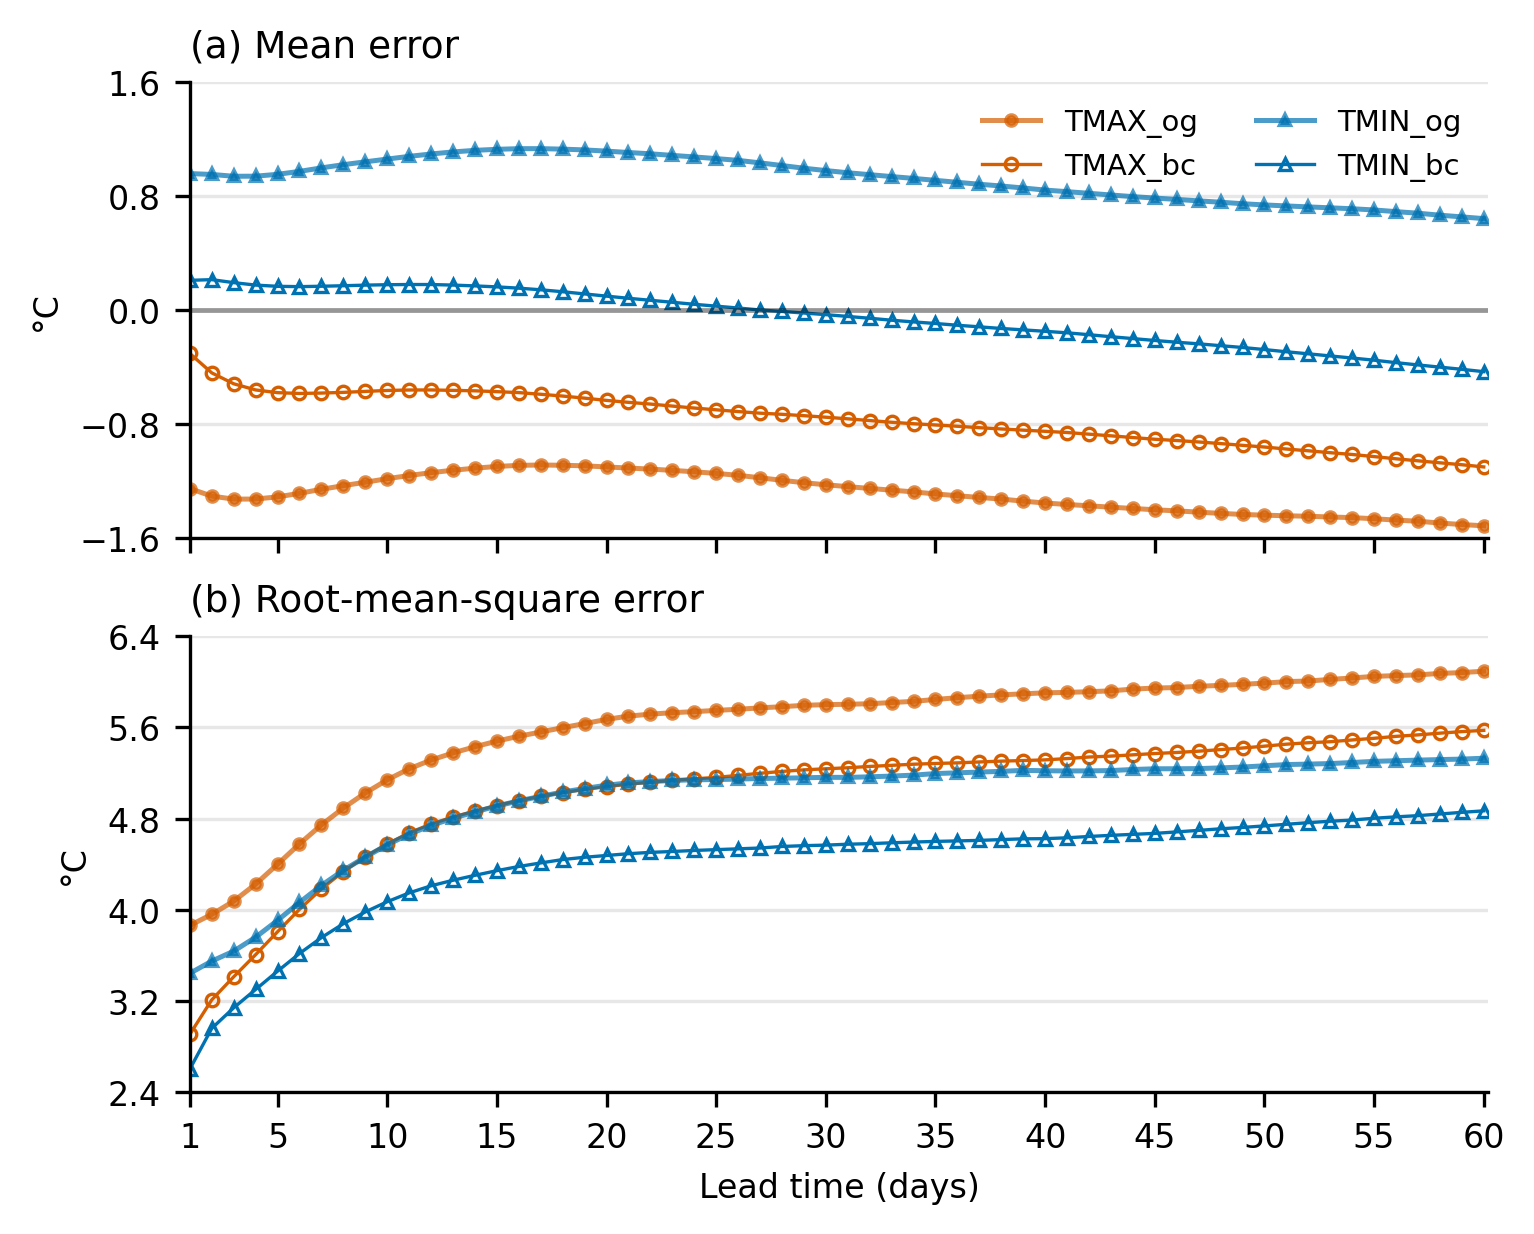

In [ ]:
# === plot metrics w.r.t forecast lead days === #
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(5, 4), sharex=True, constrained_layout=True, dpi=300)
lead_days =  merged["lead_days"]

# --- mean error
axes[0].plot(lead_days, merged["mb_tmax_og"], color="#D55E00", lw=1.2, linestyle='-',marker='o', markersize=2.5, alpha=0.7, label="TMAX_og")
axes[0].plot(lead_days, merged["mb_tmax_corr"], color="#D55E00", linestyle='-', marker='o', markerfacecolor='none', markersize=3, markeredgewidth=0.8, lw=0.8, label="TMAX_bc")
axes[0].plot(lead_days, merged["mb_tmin_og"], color="#0072B2", lw=1.2, linestyle='-', marker='^', markersize=2.5, alpha=0.7, label="TMIN_og")
axes[0].plot(lead_days, merged["mb_tmin_corr"], color="#0072B2", linestyle='-', marker='^', markerfacecolor='none',markersize=3, markeredgewidth=0.8, lw=0.8, label="TMIN_bc")

axes[0].axhline(0, color="black", lw=1.2, linestyle="-", alpha=0.35)
axes[0].set_title("(a) Mean error", loc='left', fontsize=9, fontweight='normal')
axes[0].set_ylabel("°C", fontsize=8)
axes[0].set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60])
axes[0].set_xticklabels([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60])
axes[0].set_xlim([1, 60.2])
axes[0].set_ylim([-1.6, 1.6])
axes[0].set_yticks(np.arange(-1.6, 1.8, 0.8))
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(axis="y", linewidth=0.8, alpha=0.3)
axes[0].tick_params(labelsize=8)
axes[0].legend(loc="upper right", ncols=2, fontsize=7, frameon=False)


# --- RMSE
axes[1].plot(lead_days, merged["rmse_tmax_og"], color="#D55E00", lw=1.2, linestyle='-',marker='o', markersize=2.5, alpha=0.7, label="TMAX_og")
axes[1].plot(lead_days, merged["rmse_tmax_corr"], color="#D55E00", linestyle='-', marker='o', markerfacecolor='none', markersize=3, markeredgewidth=0.8, lw=0.8, label="TMAX_bc")
axes[1].plot(lead_days, merged["rmse_tmin_og"], color="#0072B2", lw=1.2, linestyle='-', marker='^', markersize=2.5, alpha=0.7, label="TMIN_og")
axes[1].plot(lead_days, merged["rmse_tmin_corr"], color="#0072B2", linestyle='-', marker='^', markerfacecolor='none',markersize=3, markeredgewidth=0.8, lw=0.8, label="TMIN_bc")

axes[1].set_title("(b) Root-mean-square error", loc='left', fontsize=9, fontweight='normal')
axes[1].set_ylabel("°C", fontsize=8)
axes[1].set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60])
axes[1].set_xticklabels([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60])
axes[1].set_xlim([1, 60.2])
axes[1].set_ylim([2.4, 6.4])
axes[1].set_yticks(np.arange(2.4, 6.6, 0.8))
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="y", linewidth=0.8, alpha=0.3)
axes[1].tick_params(labelsize=8)
axes[1].set_xlabel("Lead time (days)", fontsize=8)



#### Plot the train_loss and val_loss with epoches

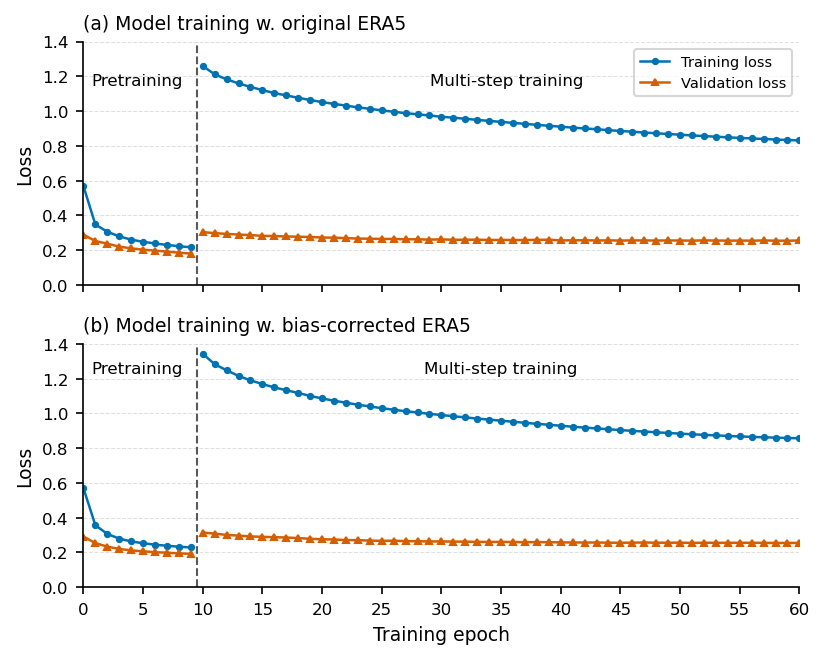

In [ ]:
# File paths
log_path = Path('Data/credit_last_experiment/')

og_pretrain_file = log_path / "ERA5_og/training_log_ERAog_pretrain.csv"
og_multitrain_file = log_path / "ERA5_og/training_log_ERAog_multitrain.csv"
corr_pretrain_file = log_path / "ERA5_corr/training_log_ERAcorr_pretrain.csv"
corr_multitrain_file = log_path / "ERA5_corr/training_log_ERAcorr_multitrain.csv"


# Read and clean one training log
def read_training_log(path):
    """
    Read a training CSV and remove empty or invalid records.
    """
    df = pd.read_csv(path)
    required_columns = ["epoch", "train_loss", "valid_loss"]
    missing = [col for col in required_columns if col not in df.columns]
    if missing:
        raise ValueError(
            f"{path} is missing required columns: {missing}"
        )
    # Convert relevant columns to numeric.
    # Invalid strings become NaN.
    for col in required_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Remove empty/interrupted rows
    df = df.dropna(
        subset=["epoch", "train_loss", "valid_loss"]
    ).copy()

    # Sort in case records were written out of order
    df = df.sort_values("epoch")
    # Keep the last occurrence if an epoch was written more than once
    df = df.drop_duplicates(subset="epoch", keep="last")
    df["epoch"] = df["epoch"].astype(int)

    return df.reset_index(drop=True)


og_pretrain = read_training_log(og_pretrain_file)
og_multitrain = read_training_log(og_multitrain_file)
corr_pretrain = read_training_log(corr_pretrain_file)
corr_multitrain = read_training_log(corr_multitrain_file)


# Create a continuous epoch axis
# Pretraining epochs remain 0, 1, ..., 9
og_pretrain["global_epoch"] = np.arange(len(og_pretrain))
corr_pretrain["global_epoch"] = np.arange(len(corr_pretrain))

# Multi-step training begins immediately after pretraining
og_phase2_start = len(og_pretrain)
corr_phase2_start = len(corr_pretrain)

og_multitrain["global_epoch"] = (np.arange(len(og_multitrain)) + og_phase2_start)
corr_multitrain["global_epoch"] = (np.arange(len(corr_multitrain)) + corr_phase2_start)


# Plot

fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(5.6, 4.5), sharex=True, dpi=150)

train_color = "#0072B2"
valid_color = "#D55E00"

# Draw each phase separately so the phase transition is not
# connected by an artificial line.
ax[0].plot(og_pretrain["global_epoch"], og_pretrain["train_loss"], color=train_color, linewidth=1.2, marker="o", markersize=2.5, label="Training loss")
ax[0].plot(og_pretrain["global_epoch"], og_pretrain["valid_loss"], color=valid_color, linewidth=1.2, marker="^", markersize=2.5, label="Validation loss")
ax[0].plot(og_multitrain["global_epoch"], og_multitrain["train_loss"], color=train_color, linewidth=1.2, marker="o", markersize=2.5,)
ax[0].plot(og_multitrain["global_epoch"], og_multitrain["valid_loss"], color=valid_color, linewidth=1.2, marker="^", markersize=2.5,)
# Phase boundary
boundary = og_phase2_start - 0.5
ax[0].axvline(boundary, color="0.35", linestyle="--", linewidth=1.0,)
# Phase labels
ymax = max(
    og_multitrain["train_loss"].max(),
    og_multitrain["valid_loss"].max(),
)

ax[0].text((og_phase2_start - 1) / 2, ymax * 0.97, "Pretraining", ha="center", va="top", fontsize=8, fontweight="normal",)
ax[0].text(og_phase2_start + (len(og_multitrain) - 1) / 2, ymax * 0.97, "Multi-step training", ha="center", va="top",
    fontsize=8, fontweight="normal",)

# Formatting
#ax[0].set_xlabel("Training epoch", fontsize=9)
ax[0].set_xlim([0, 60])
ax[0].set_ylabel("Loss", fontsize=9)
ax[0].set_yticks(np.arange(0, 1.5, 0.2))
ax[0].set_yticklabels([0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4])
ax[0].set_ylim([0, 1.4])
ax[0].set_title( "(a) Model training w. original ERA5", loc="left", fontsize=9, fontweight="normal",)
ax[0].legend(loc="upper right", frameon=True, fontsize=7,)
ax[0].grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4,)
ax[0].tick_params(labelsize=8)
ax[0].spines["top"].set_visible(False)
ax[0].spines["right"].set_visible(False)


# Draw each phase separately so the phase transition is not
# connected by an artificial line.
ax[1].plot(corr_pretrain["global_epoch"], corr_pretrain["train_loss"], color=train_color, linewidth=1.2, marker="o", markersize=2.5, label="Training loss")
ax[1].plot(corr_pretrain["global_epoch"], corr_pretrain["valid_loss"], color=valid_color, linewidth=1.2, marker="^", markersize=2.5, label="Validation loss")
ax[1].plot(corr_multitrain["global_epoch"], corr_multitrain["train_loss"], color=train_color, linewidth=1.2, marker="o", markersize=2.5,)
ax[1].plot(corr_multitrain["global_epoch"], corr_multitrain["valid_loss"], color=valid_color, linewidth=1.2, marker="^", markersize=2.5,)
# Phase boundary
boundary = corr_phase2_start - 0.5
ax[1].axvline(boundary, color="0.35", linestyle="--", linewidth=1.0,)
# Phase labels
ymax = max(
    corr_multitrain["train_loss"].max(),
    corr_multitrain["valid_loss"].max(),
)

ax[1].text((corr_phase2_start - 1) / 2, ymax * 0.97, "Pretraining", ha="center", va="top", fontsize=8, fontweight="normal",)
ax[1].text(corr_phase2_start + (len(corr_multitrain) - 1) / 2, ymax * 0.97, "Multi-step training", ha="center", va="top",
    fontsize=8, fontweight="normal",)

# Formatting
ax[1].set_xlabel("Training epoch", fontsize=9)
ax[1].set_ylabel("Loss", fontsize=9)
ax[1].set_title( "(b) Model training w. bias-corrected ERA5", loc="left", fontsize=9, fontweight="normal",)
#ax[1].legend(loc="upper right", frameon=False, fontsize=7,)
ax[1].grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4,)
ax[1].set_xticks(np.arange(0, 61, 5))
ax[1].set_xticklabels(np.arange(0, 61, 5))
ax[1].set_xlim([0, 60])
ax[1].set_yticks(np.arange(0, 1.6, 0.20))
ax[1].set_yticklabels([0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4])
ax[1].set_ylim([0, 1.4])
ax[1].tick_params(labelsize=8)
ax[1].spines["top"].set_visible(False)
ax[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()